In [1]:
 !nvidia-smi

Fri Sep  4 11:08:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
import socket
import tensorflow as tf

print("hostname:", socket.gethostname())
print("current path:", os.getcwd())
print("gpus:", tf.config.list_physical_devices("GPU"))

hostname: 0247301ac01c
current path: /content
gpus: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# official shared project folder on google drive
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/FDL Project"

# temporary local working copy inside the colab runtime
# this folder is deleted when the runtime stops, so it does not replace the shared dataset.
LOCAL_PROJECT_DIR = "/content/fdl_project"

DRIVE_DATA_DIR = f"{DRIVE_PROJECT_DIR}/data/flower_photos"
LOCAL_DATA_DIR = f"{LOCAL_PROJECT_DIR}/data/flower_photos"

DRIVE_SPLIT_DIR = f"{DRIVE_PROJECT_DIR}/data/splits"
LOCAL_SPLIT_DIR = f"{LOCAL_PROJECT_DIR}/data/splits"

# training reads images and split csv files from the local colab disk
PROJECT_DIR = LOCAL_PROJECT_DIR
DATA_DIR = LOCAL_DATA_DIR
SPLIT_DIR = LOCAL_SPLIT_DIR

# shared outputs and scripts stay on google drive
MODEL_DIR = f"{DRIVE_PROJECT_DIR}/models"
SCRIPT_DIR = f"{DRIVE_PROJECT_DIR}/scripts"
PLOT_DIR = f"{DRIVE_PROJECT_DIR}/plots"
HISTORY_DIR = f"{DRIVE_PROJECT_DIR}/history"

print("training project dir:", PROJECT_DIR)
print("training data dir:", DATA_DIR)
print("training split dir:", SPLIT_DIR)
print("shared model dir:", MODEL_DIR)

training project dir: /content/fdl_project
training data dir: /content/fdl_project/data/flower_photos
training split dir: /content/fdl_project/data/splits
shared model dir: /content/drive/MyDrive/FDL Project/models


## copy shared data to local colab disk

this cell keeps google drive as the official shared source, but copies `flower_photos` and `splits` to `/content` so training reads from the faster local runtime disk.

In [5]:
import os
import glob
import shutil
import zipfile
import subprocess
import pandas as pd

os.makedirs(f"{LOCAL_PROJECT_DIR}/data", exist_ok=True)

DRIVE_ZIP_PATH = f"{DRIVE_PROJECT_DIR}/data/flower_photos.zip"
LOCAL_ZIP_PATH = f"{LOCAL_PROJECT_DIR}/data/flower_photos.zip"

# se il dataset è già stato copiato nella runtime, non rifare tutto
if os.path.exists(LOCAL_DATA_DIR) and len(glob.glob(f"{LOCAL_DATA_DIR}/**/*", recursive=True)) > 3000:
    print("local dataset already available, skipping copy")
else:
    # crea lo zip su drive solo la prima volta
    if not os.path.exists(DRIVE_ZIP_PATH):
        print("creating dataset zip on drive, this is done only once...")
        shutil.make_archive(
            base_name=DRIVE_ZIP_PATH.replace(".zip", ""),
            format="zip",
            root_dir=DRIVE_DATA_DIR
        )

    print("copying zip from drive to local colab disk...")
    shutil.copy2(DRIVE_ZIP_PATH, LOCAL_ZIP_PATH)

    print("extracting dataset locally...")
    if os.path.exists(LOCAL_DATA_DIR):
        shutil.rmtree(LOCAL_DATA_DIR)

    os.makedirs(LOCAL_DATA_DIR, exist_ok=True)

    with zipfile.ZipFile(LOCAL_ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(LOCAL_DATA_DIR)

# copia gli split
if os.path.exists(LOCAL_SPLIT_DIR):
    shutil.rmtree(LOCAL_SPLIT_DIR)

shutil.copytree(DRIVE_SPLIT_DIR, LOCAL_SPLIT_DIR)

# aggiorna eventuali path assoluti nei csv degli split
for csv_path in glob.glob(f"{LOCAL_SPLIT_DIR}/*.csv"):
    df = pd.read_csv(csv_path)

    if "image_path" in df.columns:
        df["image_path"] = (
            df["image_path"]
            .astype(str)
            .str.replace(DRIVE_DATA_DIR, LOCAL_DATA_DIR, regex=False)
            .str.replace(f"{DRIVE_PROJECT_DIR}/data/flower_photos", LOCAL_DATA_DIR, regex=False)
        )

        df.to_csv(csv_path, index=False)

n_images = sum(
    len(files)
    for _, _, files in os.walk(LOCAL_DATA_DIR)
)

print(f"local dataset ready: {LOCAL_DATA_DIR}")
print(f"number of copied files: {n_images}")
print(f"local splits ready: {LOCAL_SPLIT_DIR}")

copying zip from drive to local colab disk...
extracting dataset locally...
local dataset ready: /content/fdl_project/data/flower_photos
number of copied files: 3666
local splits ready: /content/fdl_project/data/splits


In [6]:
import sys
import os
import json
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [7]:
if SCRIPT_DIR not in sys.path:
    sys.path.append(SCRIPT_DIR)

from preprocessing import load_common_datasets

## local copy smoke test

run this cell after the copy step to verify that the notebook is actually loading batches from the local colab path and that images are still in the expected `[0, 255]` range before the mobilenetv2-specific preprocessing.

In [8]:
sample_train_ds, sample_val_ds, _, sample_class_names = load_common_datasets(
    project_dir=PROJECT_DIR,
    val_fold=0,
    img_size=IMG_SIZE[0] if "IMG_SIZE" in globals() else 224,
    batch_size=BATCH_SIZE if "BATCH_SIZE" in globals() else 32,
    normalization=None,
    train_file_name="train_folds_v3.csv",
    shuffle_train=False,
)

sample_images, sample_labels = next(iter(sample_train_ds))

print("class names:", sample_class_names)
print("sample image batch shape:", sample_images.shape)
print("sample label batch shape:", sample_labels.shape)
print("sample pixel range:", float(tf.reduce_min(sample_images)), float(tf.reduce_max(sample_images)))
print("using local project dir:", PROJECT_DIR)
print("normalization in shared loader: none")

class names: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']
sample image batch shape: (32, 224, 224, 3)
sample label batch shape: (32,)
sample pixel range: 0.0 255.0
using local project dir: /content/fdl_project
normalization in shared loader: none


## Initialize Constants

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CURRENT_DATE = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# v5.2 image-based head comparison: MobileNetV2 frozen + data augmentation + ReduceLROnPlateau, using v3 splits.
MODEL_NAME = "MobileNetV2"
MODEL_VERSION = "v5.2_augmentation_clean_distributed_v3_reduce_lr"
MODEL_FILE_NAME = f"{MODEL_NAME}_{MODEL_VERSION}"

# transfer learning experiment configuration
BACKBONE_NAME = "MobileNetV2"
HEAD_TYPES = ["simple", "medium", "heavy"]
LEARNING_RATE = 1e-3
EPOCHS = 30

# Reduce learning rate when validation loss reaches a plateau before early stopping.
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 2
REDUCE_LR_MIN_DELTA = 1e-4
REDUCE_LR_MIN_LR = 1e-6
EARLY_STOPPING_PATIENCE = 6

# keep shared preprocessing without normalization.
# MobileNetV2-specific normalization to [-1, 1] stays inside the model.
INPUT_NORMALIZATION = None


In [10]:
# Create a directory to save your models if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)

## Define Data Augmentation

In [11]:
# TO DO : If needed, change this but must be changed in all notebooks
# Moderate augmentation: applied only during training when it is inside the model.

DATA_AUGMENTATION = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.2),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
    keras.layers.RandomBrightness(0.2)
], name="data_augmentation_pipeline")

## Define Initialize model Function

In [12]:
def build_classification_head(x, num_classes, head_type="simple"):
  """
  Classification head used on top of the frozen MobileNetV2 convolutional backbone.

  v2.0 compares head capacity while keeping regularization comparable:
  - simple: linear classifier on pooled pretrained features
  - medium: one hidden Dense layer
  - heavy: two hidden Dense layers

  BatchNormalization and L2 are intentionally removed from medium/heavy so
  the experiment tests head capacity rather than capacity plus extra penalties.
  """

  x = keras.layers.GlobalAveragePooling2D(name="gap")(x)

  if head_type == "simple":
    x = keras.layers.Dropout(0.2, name="dropout_02")(x)

  elif head_type == "medium":
    x = keras.layers.Dense(128, activation="relu", name="dense_128_relu")(x)
    x = keras.layers.Dropout(0.2, name="dropout_02")(x)

  elif head_type == "heavy":
    x = keras.layers.Dense(256, activation="relu", name="dense_256_relu")(x)
    x = keras.layers.Dropout(0.3, name="dropout_03_after_256")(x)
    x = keras.layers.Dense(128, activation="relu", name="dense_128_relu")(x)
    x = keras.layers.Dropout(0.2, name="dropout_02_after_128")(x)

  else:
    raise ValueError(f"unknown head_type: {head_type}. choose one of: {HEAD_TYPES}")

  outputs = keras.layers.Dense(num_classes, activation="softmax", name="predictions")(x)
  return outputs


def initialize_model(input_shape=(224, 224, 3), num_classes=2, augmentation_pipeline=None, head_type="simple", show_summary=True):
  """
  MobileNetV2 transfer learning model for image-based training.

  important:
  - weights="imagenet" means the backbone is pretrained on imagenet, not on our flower_photos dataset.
  - include_top=False removes the imagenet classification head.
  - backbone.trainable=False freezes the pretrained convolutional feature extractor.
  - preprocessing is inside the model, so the shared preprocessing keeps normalization=None.
  """

  inputs = keras.layers.Input(shape=input_shape, name="input_image")
  x = inputs

  # data augmentation is used for every head during training.
  if augmentation_pipeline is not None:
    x = augmentation_pipeline(x)

  # MobileNetV2-specific preprocessing inside the model.
  # it converts pixel values in [0, 255] to the [-1, 1] range expected by MobileNetV2.
  x = keras.layers.Rescaling(scale=1./127.5, offset=-1.0, name="mobilenetv2_preprocessing")(x)

  backbone = keras.applications.MobileNetV2(
      input_shape=input_shape,
      include_top=False,
      weights="imagenet"
  )
  backbone.trainable = False

  # training=False keeps batch normalization layers in inference mode while the backbone is frozen.
  x = backbone(x, training=False)

  outputs = build_classification_head(x, num_classes=num_classes, head_type=head_type)
  model = keras.Model(inputs=inputs, outputs=outputs, name=f"{MODEL_NAME}_{head_type}")

  if show_summary:
    model.summary()

  model.compile(
      optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"]
  )

  return model


## Get Number of Folds

In [13]:
df_main = pd.read_csv(f"{SPLIT_DIR}/train_folds_v3.csv", dtype={"image_path": str, "fold": int})
unique_folds = sorted(df_main["fold"].unique())
print(f"found folds: {unique_folds}")
print(f"starting {len(unique_folds)}-fold validation for head selection")

found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
starting 5-fold validation for head selection


## Define Save Model Function

In [14]:
def save_model(model, current_fold, head_type):
  model_name = f"{MODEL_FILE_NAME}_{head_type}_fold_{current_fold}_{CURRENT_DATE}.keras"
  save_path = os.path.join(MODEL_DIR, model_name)

  model.save(save_path)
  print(f"Saved model to: {save_path}")

  return save_path

In [15]:
#Another test
print("project dir:", PROJECT_DIR)
print("data dir:", DATA_DIR)
print("split dir:", SPLIT_DIR)
print("input normalization:", INPUT_NORMALIZATION)

project dir: /content/fdl_project
data dir: /content/fdl_project/data/flower_photos
split dir: /content/fdl_project/data/splits
input normalization: None


In [16]:
# Run for the full experiment
HEAD_TYPES = ["simple", "medium", "heavy"]
EPOCHS = 30


## Model Training (with Cross Validation)

Train MobileNetV2 with frozen backbone and data augmentation for each classification head. Head selection uses validation loss only.


## Image-Based Head Comparison


In [17]:
all_fold_histories = []
all_results = []
saved_model_paths = {}

NUM_FOLDS = len(unique_folds)

print("\nimage-based head comparison with data augmentation")

for head_type in HEAD_TYPES:
  print(f"\n==================== TRAINING HEAD: {head_type.upper()} ====================")

  for current_fold in unique_folds:
    print(f"\n========== head {head_type} | fold {current_fold} / {NUM_FOLDS - 1} ==========")

    train_ds, val_ds, _, class_names = load_common_datasets(
        project_dir=PROJECT_DIR,
        val_fold=current_fold,
        img_size=IMG_SIZE[0],
        batch_size=BATCH_SIZE,
        normalization=INPUT_NORMALIZATION,
        train_file_name="train_folds_v3.csv",
        shuffle_train=True,
    )

    model = initialize_model(
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
        num_classes=len(class_names),
        augmentation_pipeline=DATA_AUGMENTATION,
        head_type=head_type,
        show_summary=(head_type == HEAD_TYPES[0] and current_fold == unique_folds[0]),
    )

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1,
    )

    reduce_lr = ReduceLROnPlateau(
        monitor="val_loss",
        factor=REDUCE_LR_FACTOR,
        patience=REDUCE_LR_PATIENCE,
        min_delta=REDUCE_LR_MIN_DELTA,
        min_lr=REDUCE_LR_MIN_LR,
        verbose=1,
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[reduce_lr, early_stopping],
    )

    all_fold_histories.append({
        "phase": "image_based_head_comparison",
        "head_type": head_type,
        "fold": current_fold,
        "history": history.history,
    })

    best_epoch_idx = int(np.argmin(history.history["val_loss"]))
    all_results.append({
        "head_type": head_type,
        "fold": current_fold,
        "best_epoch": best_epoch_idx + 1,
        "best_val_loss": float(history.history["val_loss"][best_epoch_idx]),
        "best_val_accuracy": float(history.history["val_accuracy"][best_epoch_idx]),
        "epochs_trained": len(history.history["loss"]),
    })

    save_path = save_model(model, current_fold, head_type)
    saved_model_paths[(head_type, current_fold)] = save_path

    del model
    keras.backend.clear_session()

results_df = pd.DataFrame(all_results)
display(results_df)

head_summary_df = (
    results_df
    .groupby("head_type")
    .agg(
        mean_val_loss=("best_val_loss", "mean"),
        std_val_loss=("best_val_loss", "std"),
        mean_val_accuracy=("best_val_accuracy", "mean"),
        std_val_accuracy=("best_val_accuracy", "std"),
        mean_best_epoch=("best_epoch", "mean"),
    )
    .sort_values("mean_val_loss", ascending=True)
)

display(head_summary_df)

BEST_HEAD_TYPE = head_summary_df.index[0]
print(f"best head selected using image-based validation loss only: {BEST_HEAD_TYPE}")
print("test set evaluation removed from this notebook.")
print("the test set should be used only once later, when comparing the final selected models across architectures.")



image-based head comparison with data augmentation

==================== TRAINING HEAD: SIMPLE ====================

========== head simple | fold 0 / 4 ==========
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation_pipeline      │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_preprocessing       │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_02 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 24s 117ms/step - accuracy: 0.6374 - loss: 0.9673 - val_accuracy: 0.8085 - val_loss: 0.5385 - learning_rate: 0.0010
Epoch 2/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 85ms/step - accuracy: 0.8273 - loss: 0.5036 - val_accuracy: 0.8546 - val_loss: 0.4128 - learning_rate: 0.0010
Epoch 3/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - accuracy: 0.8562 - loss: 0.4163 - val_accuracy: 0.8635 - val_loss: 0.3902 - learning_rate: 0.0010
Epoch 4/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 8s 110ms/step - accuracy: 0.8726 - loss: 0.3743 - val_accuracy: 0.8918 - val_loss: 0.3341 - learning_rate: 0.0010
Epoch 5/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8810 - loss: 0.3340 - val_accuracy: 0.8865 - val_loss: 0.3254 - learning_rate: 0.0010
Epoch 6/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - accuracy: 0.8873 - loss: 0.3125 - val_accuracy: 0.8901 - val_loss: 0.3095 - learning_rate: 0.0010
Epoch 7/30
71/71 ━━━━━━━━━━━━━━━━━━━━ 6s 82ms/step - accuracy: 0.8948 - loss: 0.2963 - val_

,head_type,fold,best_epoch,best_val_loss,best_val_accuracy,epochs_trained
0,simple,0,21,0.273614,0.916667,27
1,simple,1,18,0.321371,0.877660,24
2,simple,2,17,0.302322,0.896980,23
3,simple,3,22,0.282838,0.920071,28
4,simple,4,20,0.225546,0.923623,26
5,medium,0,10,0.283672,0.913121,16
6,medium,1,14,0.322484,0.884752,20
7,medium,2,11,0.293978,0.909414,17
8,medium,3,20,0.294949,0.900533,26
9,medium,4,20,0.212301,0.918295,26


,mean_val_loss,std_val_loss,mean_val_accuracy,std_val_accuracy,mean_best_epoch
head_type,,,,,
heavy,0.277952,0.046585,0.904869,0.016252,7.6
simple,0.281138,0.036116,0.907000,0.019377,19.6
medium,0.281477,0.041260,0.905223,0.013152,15.0


best head selected using image-based validation loss only: heavy
test set evaluation removed from this notebook.
the test set should be used only once later, when comparing the final selected models across architectures.


## Save Results

In [18]:
def plot_cv_results(all_fold_histories, head_type=None):
    ACCURACY_Y_LIMITS = (0.6, 1.0)
    LOSS_Y_LIMITS = (0.0, 1.1)
    max_epochs = max(len(item["history"]["accuracy"]) for item in all_fold_histories)

    if head_type is not None:
        histories_to_plot = [item for item in all_fold_histories if item["head_type"] == head_type]
        title_suffix = f" - {head_type} head"
    else:
        histories_to_plot = all_fold_histories
        title_suffix = ""

    if len(histories_to_plot) == 0:
        print("No histories to plot.")
        return

    plt.figure(figsize=(14, 5))

    # PLOT 1: ACCURACY
    plt.subplot(1, 2, 1)
    for item in histories_to_plot:
        history = item["history"]
        label_prefix = f"{item['head_type']} | Fold {item['fold']}"
        plt.plot(history["accuracy"], label=f"Train {label_prefix}", linestyle="--")
        plt.plot(history["val_accuracy"], label=f"Val {label_prefix}", linewidth=2)
    plt.title(f"Training and Validation Accuracy{title_suffix}")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.ylim(*ACCURACY_Y_LIMITS)
    plt.xlim(0, max_epochs - 1)
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)

    # PLOT 2: LOSS
    plt.subplot(1, 2, 2)
    for item in histories_to_plot:
        history = item["history"]
        label_prefix = f"{item['head_type']} | Fold {item['fold']}"
        plt.plot(history["loss"], label=f"Train {label_prefix}", linestyle="--")
        plt.plot(history["val_loss"], label=f"Val {label_prefix}", linewidth=2)
    plt.title(f"Training and Validation Loss{title_suffix}")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.ylim(*LOSS_Y_LIMITS)
    plt.xlim(0, max_epochs - 1)
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.3)

    plt.savefig(f"{PLOT_DIR}/{MODEL_FILE_NAME}.png", dpi=300, bbox_inches='tight')

    plt.tight_layout()
    plt.show()

In [19]:
def save_cv_history(histories, filepath):
    def native_convert(obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, (np.int32, np.int64)):
            return int(obj)
        raise TypeError(f"object of type {type(obj)} is not json serializable")

    with open(filepath, "w") as f:
        json.dump(histories, f, default=native_convert, indent=4)

    print(f"history successfully saved to {filepath}")

In [20]:
save_cv_history(all_fold_histories, f"{HISTORY_DIR}/{MODEL_FILE_NAME}_history.json")

results_df.to_csv(f"{HISTORY_DIR}/{MODEL_FILE_NAME}_results.csv", index=False)
head_summary_df.to_csv(f"{HISTORY_DIR}/{MODEL_FILE_NAME}_head_summary.csv")

print("saved image-based head comparison results to drive history folder")


history successfully saved to /content/drive/MyDrive/FDL Project/history/MobileNetV2_v5.2_augmentation_clean_distributed_v3_reduce_lr_history.json
saved image-based head comparison results to drive history folder


/tmp/ipykernel_795/2446216539.py:51: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


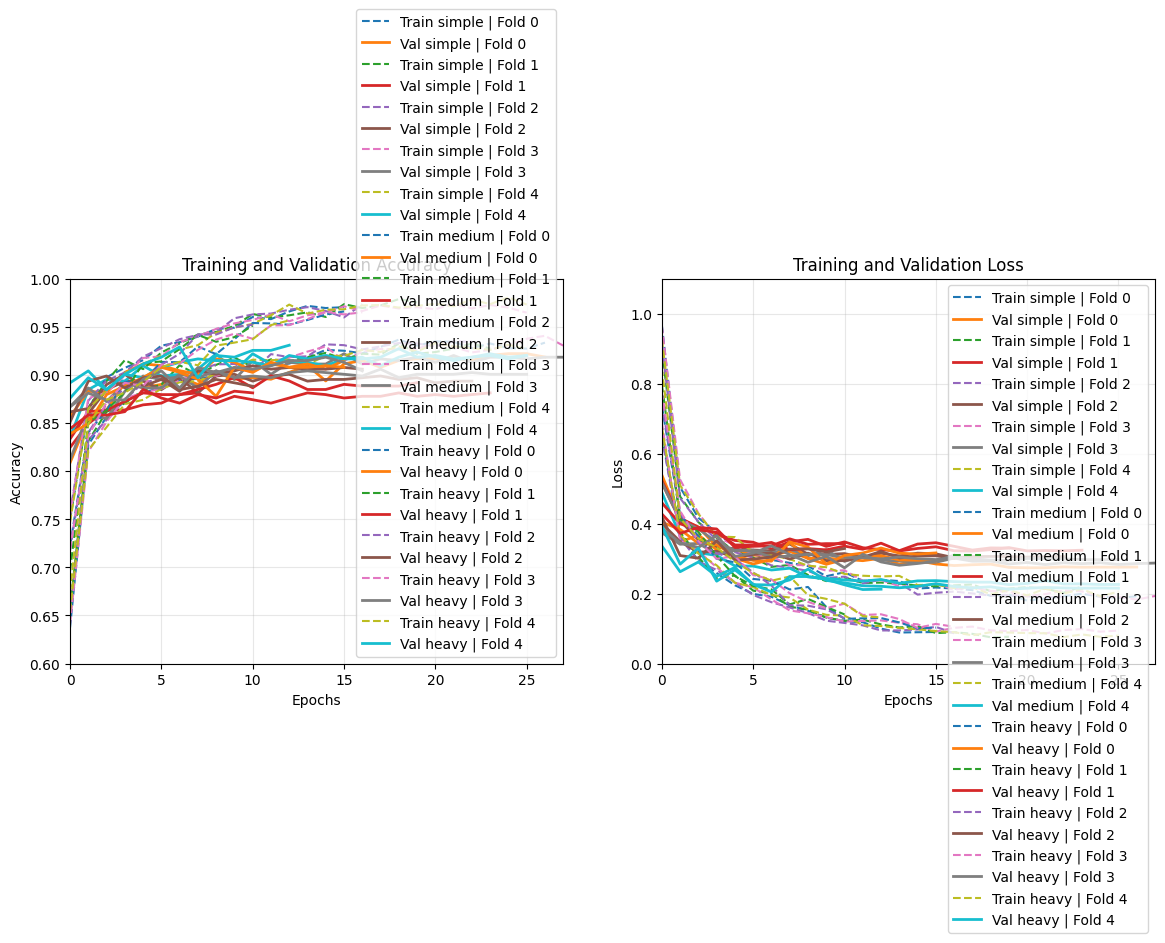

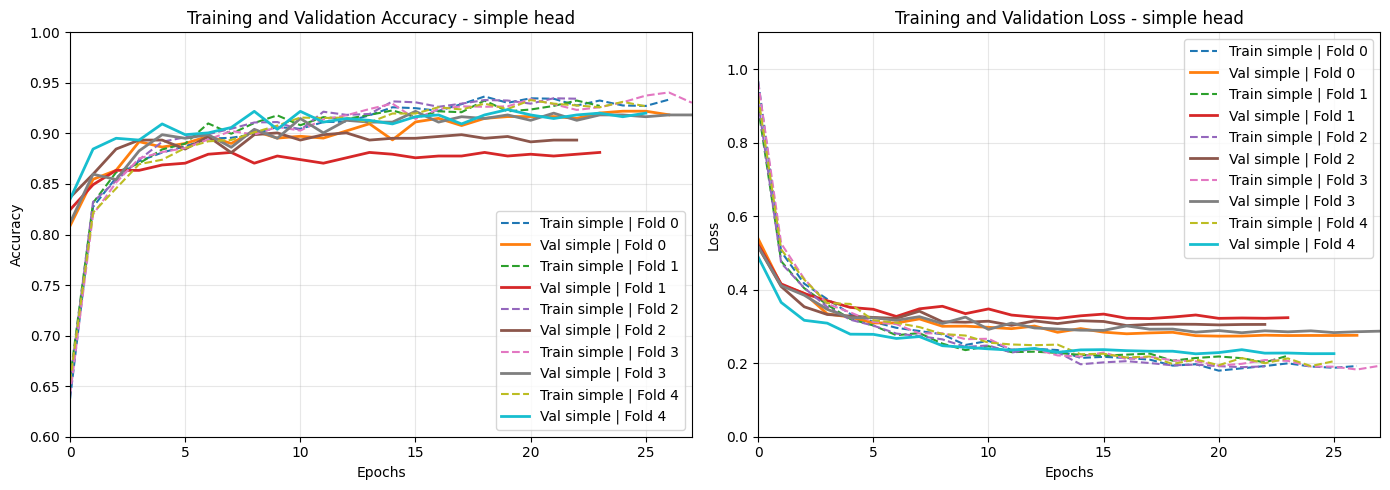

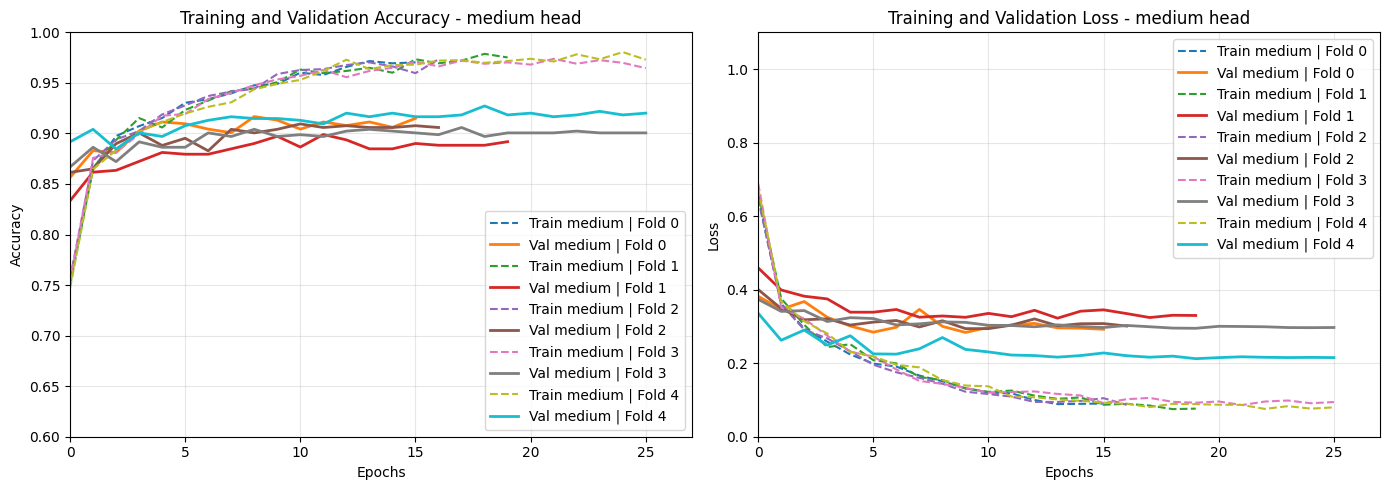

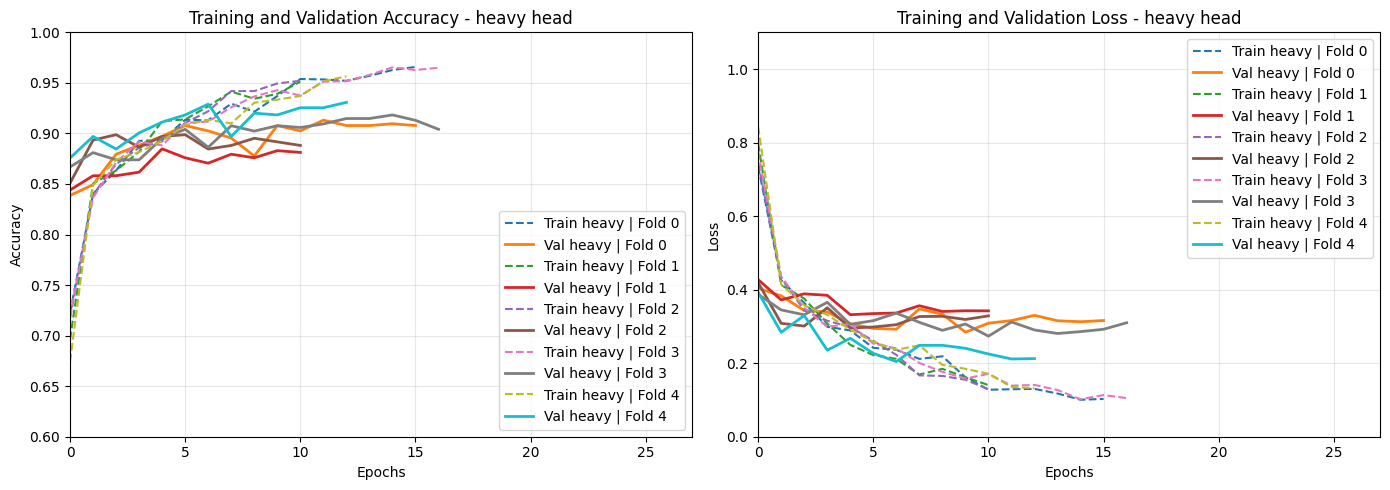

selected head for mobilenetv2: heavy


In [21]:
plot_cv_results(all_fold_histories)

for head_type in HEAD_TYPES:
  plot_cv_results(all_fold_histories, head_type=head_type)

print(f"selected head for mobilenetv2: {BEST_HEAD_TYPE}")
